## **一、这一周要理解的完整过程**

本笔记对应 S1 第一周：从“为什么噪声能变成图像”走到可以检查的数学、核心参考代码和真实 MNIST 短训练。主要来源是 [DDPM 原论文](https://arxiv.org/abs/2006.11239) 的第 2–3 节及算法 1、2，以及 [作者实现](https://github.com/hojonathanho/diffusion)。文字与代码为本项目的教学整理，不是原论文的大规模复现。

**学习边界**：你已授权本笔记展示完整参考 Scheduler，但 `src/minigen/objectives/ddpm_scheduler.py` 仍留给你亲手实现。下面会明确构造 `TeachingDDPMScheduler` 并传给训练器；项目 CLI 不会自动切换到它。数学验证通过、教学短训完成、项目核心通过和你能脱稿解释，是四种不同的进度。

**阅读方式**：先读前三章理解信息流，再推后验与损失，运行数学检查，最后读训练和采样结果。每个公式定义符号，每个代码块说明输入输出。输出由真实内核执行产生，样本好坏以保存结果为准。

### **1. 从一个具体问题开始**

我们希望随机生成一张新的手写数字图，而不是从数据集中随机抽一张。数据里只有干净图片，没有“从噪声到图片”的答案序列。DDPM（Denoising Diffusion Probabilistic Model，去噪扩散概率模型）先人为规定一个容易计算的 **前向加噪过程**，把干净图逐步扰动成接近高斯噪声；再训练一个共享网络，在给定噪声强度时预测噪声。生成时，利用网络的预测计算反向转移分布，逐步得到图像。

“预测噪声”并不等于网络知道当时实际抽到的全部随机数。网络只看到带噪图和时间，同一个带噪输入可能对应多张干净图，因此它通过回归学习条件统计信息。采样器把这些信息转成反向分布，并在大部分步骤继续引入随机性。

| 阶段 | 已知输入 | 需要做什么 | 是否更新网络 |
| --- | --- | --- | --- |
| 数据准备 | 干净 MNIST 图像 | 转成 `[B,1,28,28]`，像素映射到 `[-1,1]` | 否 |
| 前向加噪 | 干净图、时间、自己抽的噪声 | 构造监督输入 | 否 |
| 训练 | 带噪图、时间；抽取的噪声作为标签 | 让 U-Net 预测噪声并优化参数 | 是 |
| 生成 | 新高斯噪声、已训练网络 | 用反向分布完整走过 1000 步 | 否 |

这里的“1000”是噪声过程的长度，不是模型训练更新次数。每次参数更新通常只随机抽一个时间，不需要反向传播穿过完整的 1000 步采样链。

### **2. 环境、路径与复现边界**

从项目环境运行本 Notebook。以下单元自动找到项目根目录，固定种子，使用可用的 MPS/CUDA，否则使用 CPU；不会把跨设备结果说成逐位相同。所有真实数据、权重和大型日志保存在忽略目录，必要图像嵌入笔记。

In [1]:
import copy
import json
import math
import os
import platform
import time
from pathlib import Path

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in candidates if (p / "pyproject.toml").exists() and (p / "src/minigen").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("请在 MiniGen 目录或其子目录运行")
os.chdir(ROOT)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from minigen.data.mnist import prepare_mnist
from minigen.models.tiny_unet import TinyUNet
from minigen.samplers.ddpm_loop import sample_ddpm
from minigen.training.denoising import TrainConfig, seed_all, train_denoiser

SEED = 20261026
seed_all(SEED)
torch.set_num_threads(2)
DEVICE = (
    "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
)
OUT = ROOT / "artifacts/runs/s1_week1"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
print(
    {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "device": DEVICE,
        "root": str(ROOT),
        "scheduler_source": "notebook_reference",
    }
)

{'python': '3.12.14', 'torch': '2.14.1', 'device': 'mps', 'root': '/Users/lucius/projects/personal/MiniGen', 'scheduler_source': 'notebook_reference'}


### **3. 训练与采样的数据流直觉**

训练的数据流为：干净图 $x_0$ → 抽时间 $t$ 与噪声 $\epsilon$ → 直接构造 $x_t$ → U-Net $(x_t,t)$ → 噪声预测 $\epsilon_\theta$ → 与已知噪声做 MSE → 反向传播。每张图在不同更新中可以看到不同噪声与不同时间，监督标签由我们自己产生。

生成的数据流为：新噪声 $x_T$ → U-Net 预测噪声 → 计算反向均值与方差 → 抽取 $x_{T-1}$ → 重复到 $x_0$。同一网络权重在所有时间复用，时间嵌入让网络知道现在噪声强度处在哪一档。

想象你看到一个模糊数字，网络预测哪些成分更像随机噪声；采样器据此做一小步修正。这个直觉不意味着每步都能看到更清楚的数字，也不意味着单次预测就能恢复唯一真图。可计算的反向分布和多步轨迹才是后面要推导的关键。

## **二、概率对象、符号与索引**

### **1. 高斯噪声、条件概率与张量**

$x_0$ 表示一张干净图，数学上可把它拉成 $d=28\times28=784$ 维向量；代码保留通道与空间维度。$B$ 是 batch 大小，$\theta$ 是共享 U-Net 参数，$T=1000$ 为噪声级别数。$\epsilon\sim\mathcal N(0,I)$ 表示各维独立、均值 0、方差 1 的标准高斯噪声，$I$ 是单位协方差矩阵。

若 $y=a x+b\epsilon$ 且给定 $x$，则 $x$ 是常量，噪声期望为 0，所以条件均值为 $ax$，条件协方差为 $b^2 I$。**标准差是 $b$，方差是 $b^2$**，这是实现采样时最常见的混淆。

条件概率 $q(x_t\mid x_0)$ 描述给定同一干净图、重复抽噪声时，带噪图的分布；它不是网络输出的概率标签。$\mathbb E$ 表示对随机变量取平均，实际训练用有限 batch 近似这个平均。$\lVert v\rVert_2^2$ 是各维平方之和，代码中还会说明何时除以维度。

### **2. 论文时间与代码索引的对应**

| 含义 | 数学时间 | 代码索引 | 说明 |
| --- | --- | --- | --- |
| 干净图 | $t=0$ | 无对应噪声数组项 | 累计信号系数人为定义为 1 |
| 加噪一次 | $t=1$ | `k=0` | 已有噪声，不是干净图 |
| 加噪两次 | $t=2$ | `k=1` | 使用数组前两项累计乘积 |
| 最强噪声 | $t=T$ | `k=T-1` | 接近标准高斯，通常不是严格等于 |
| 反向最后一步 | $t=1$ | `k=0` | 不再额外加入随机噪声 |

定义 $\beta_t\in(0,1)$ 为第 $t$ 步噪声方差，$\alpha_t=1-\beta_t$，$\bar\alpha_t=\prod_{s=1}^t\alpha_s$，并设 $\bar\alpha_0=1$。注意 $\alpha_t$ 是单步信号方差系数，$\bar\alpha_t$ 才是累计系数。

代码的 `timesteps` 是长度 $B$ 的 long 整数张量；不同样本可以有不同时间。取出系数后变成 `[B,1,1,1]`，在通道与空间维度广播，不能误用一个时间控制整批图。

## **三、前向过程：从递推到直接加噪**

### **1. 单步高斯转移为什么这样定义**

每步保留一部分原信号并加入独立高斯噪声：

$$q(x_t\mid x_{t-1})=\mathcal N\left(x_t;\sqrt{\alpha_t}x_{t-1},\beta_t I\right)$$

等价的采样形式为：

$$x_t=\sqrt{\alpha_t}x_{t-1}+\sqrt{\beta_t}\epsilon_t,\qquad \epsilon_t\sim\mathcal N(0,I)$$

如果输入本身是单位方差、且与新增噪声独立，输出方差为 $\alpha_t+\beta_t=1$。真实图像不必是标准高斯；这个选择让信号逐渐减弱、噪声累积，最终接近一个易采样的先验。前向分布 $q$ 是我们规定的，训练中不学习 $\beta_t$。

### **2. 完整展开两步，并推广到任意时间**

将第一步代入第二步：

$$x_1=\sqrt{\alpha_1}x_0+\sqrt{\beta_1}\epsilon_1$$

$$x_2=\sqrt{\alpha_2\alpha_1}x_0+\sqrt{\alpha_2\beta_1}\epsilon_1+\sqrt{\beta_2}\epsilon_2$$

两份噪声独立且均值为 0，所以协方差交叉项为 0，噪声总方差为 $\alpha_2\beta_1+\beta_2=\alpha_2(1-\alpha_1)+(1-\alpha_2)=1-\alpha_1\alpha_2$。独立高斯的线性组合仍为高斯，可将组合噪声重新写成一份标准高斯乘相应标准差。

推广时，假设 $x_{t-1}$ 的条件均值为 $\sqrt{\bar\alpha_{t-1}}x_0$、噪声协方差为 $(1-\bar\alpha_{t-1})I$。再加噪一次，信号系数相乘为 $\sqrt{\alpha_t\bar\alpha_{t-1}}=\sqrt{\bar\alpha_t}$，噪声方差递推为：

$$\alpha_t(1-\bar\alpha_{t-1})+\beta_t=1-\alpha_t\bar\alpha_{t-1}=1-\bar\alpha_t$$

因此：

$$q(x_t\mid x_0)=\mathcal N\left(x_t;\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right)$$

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad\epsilon\sim\mathcal N(0,I)$$

这证明了可以 **直接抽取任意时间的边际样本**，不必真的计算前面所有步骤。它不表示不同时间使用同一份噪声构成的可视化就是原始马尔可夫轨迹；后者每一步引入独立的新噪声。

### **3. 一个可手算的例子与统计验证**

> 取标量 $x_0=2$，$\beta_1=0.1$、$\beta_2=0.2$，所以 $\alpha_1=0.9$、$\alpha_2=0.8$、$\bar\alpha_2=0.72$。在数学时间 $t=2$，条件均值为 $2\sqrt{0.72}\approx1.69706$，方差为 $1-0.72=0.28$，标准差为 $\sqrt{0.28}\approx0.52915$。
>
> 当抽到 $\epsilon=-0.5$，带噪样本为 $1.69706-0.26458\approx1.43248$。这只是一个随机样本；大量重新抽噪声后的平均才接近 1.69706。

下面先用 NumPy 独立计算并重复抽样，后面再核对 PyTorch Scheduler。统计误差不应该强行要求为零。

In [2]:
rng = np.random.default_rng(SEED)
alpha_bar = (1 - 0.1) * (1 - 0.2)
mean_expected = math.sqrt(alpha_bar) * 2
variance_expected = 1 - alpha_bar
one_value = mean_expected + math.sqrt(variance_expected) * (-0.5)
many = mean_expected + math.sqrt(variance_expected) * rng.standard_normal(100000)
print(
    {
        "single_sample": one_value,
        "analytic_mean": mean_expected,
        "empirical_mean": many.mean(),
        "analytic_variance": variance_expected,
        "empirical_variance": many.var(),
    }
)
assert abs(many.mean() - mean_expected) < 0.01
assert abs(many.var() - variance_expected) < 0.01

{'single_sample': 1.4324811437412552, 'analytic_mean': 1.6970562748477143, 'empirical_mean': np.float64(1.6959442021829274), 'analytic_variance': 0.2799999999999999, 'empirical_variance': np.float64(0.2803451818119336)}


### **4. 信噪比和终点近似**

若把干净信号的参考方差视为 1，信噪比写成 $\mathrm{SNR}_t=\bar\alpha_t/(1-\bar\alpha_t)$。时间增大时，累计信号下降，网络需要处理从细微噪声到几乎纯噪声的输入。

本实验用 1000 步线性 beta，从 0.0001 到 0.02。它是一个经典基线，不保证对任意分辨率、数据和步数最优。必须检查终点信号是否足够小；如果直接把步骤减少为 10 却保留原 beta 范围，终点仍可能含大量信号，从标准高斯开始采样就不匹配训练终点。

{'terminal_alpha_bar': np.float64(4.035829765375676e-05), 'terminal_signal_scale': 0.006352818087570016}


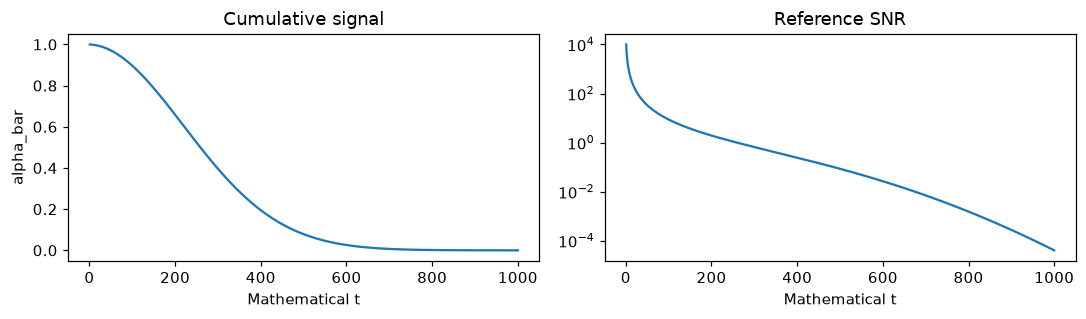

In [3]:
betas_np = np.linspace(0.0001, 0.02, 1000)
abar_np = np.cumprod(1 - betas_np)
print({"terminal_alpha_bar": abar_np[-1], "terminal_signal_scale": math.sqrt(abar_np[-1])})

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(np.arange(1, 1001), abar_np)
axes[0].set(title="Cumulative signal", xlabel="Mathematical t", ylabel="alpha_bar")
axes[1].semilogy(np.arange(1, 1001), abar_np / (1 - abar_np))
axes[1].set(title="Reference SNR", xlabel="Mathematical t")
fig.tight_layout()
fig.savefig(OUT / "noise_schedule.png")
plt.show()

## **四、反向过程：后验分布从哪里来**

### **1. 为什么不能直接得到真实反向分布**

真正生成需要 $q(x_{t-1}\mid x_t)$，但它混合了数据分布中所有可能干净图像的贡献，通常不易直接计算。训练时我们拥有 $x_0$，于是可以使用可计算的 $q(x_{t-1}\mid x_t,x_0)$ 来教网络。

两者不是同一个分布：给定 $x_0$ 消除了“这张噪图可能来自哪张真图”的不确定性。模型 $p_\theta(x_{t-1}\mid x_t)$ 在生成时只看 $x_t$ 和时间，通过学习近似边际反向分布。DDPM 选用小步高斯转移族作为模型，并固定或学习相应方差；本周采用固定后验方差基线。

### **2. 用贝叶斯和配方推导后验均值与方差**

令待求变量 $y=x_{t-1}$。根据马尔可夫性质：

$$q(y\mid x_t,x_0)\propto q(x_t\mid y)q(y\mid x_0)$$

前一项均值是 $\sqrt{\alpha_t}y$、方差是 $\beta_t I$；后一项均值是 $\sqrt{\bar\alpha_{t-1}}x_0$、方差是 $(1-\bar\alpha_{t-1})I$。忽略与 $y$ 无关的归一化因子，负对数中的二次部分为：

$$\frac{\lVert x_t-\sqrt{\alpha_t}y\rVert_2^2}{2\beta_t}+\frac{\lVert y-\sqrt{\bar\alpha_{t-1}}x_0\rVert_2^2}{2(1-\bar\alpha_{t-1})}$$

展开平方，收集 $y$ 的二次项和一次项：

$$\frac12 A_t\lVert y\rVert_2^2-b_t^\top y+\mathrm{const}$$

$$A_t=\frac{\alpha_t}{\beta_t}+\frac{1}{1-\bar\alpha_{t-1}},\qquad b_t=\frac{\sqrt{\alpha_t}}{\beta_t}x_t+\frac{\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_{t-1}}x_0$$

完成平方得到 $\frac12A_t\lVert y-b_t/A_t\rVert_2^2+\mathrm{const}$，所以方差为 $1/A_t$，均值为 $b_t/A_t$。通分后分母中的 $\alpha_t(1-\bar\alpha_{t-1})+\beta_t=1-\bar\alpha_t$，因此：

$$\widetilde\beta_t=\frac{\beta_t(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}$$

$$\widetilde\mu_t(x_t,x_0)=\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t$$

推导针对 $t\ge2$。在 $t=1$，给定 $x_0$ 的后验退化为点质量，不能把除以零的高斯密度公式直接当作普通分布计算；代码令前一累计系数为 1，得到方差 0，并在最后一步不再加噪。

### **3. 用标量精度相加独立核对**

沿用前面的例子，在数学时间 $t=2$，两份高斯对 $x_1$ 的精度分别为 $0.8/0.2=4$ 与 $1/(1-0.9)=10$，总精度为 14，因此后验方差为 $1/14\approx0.0714286$。它不是前向单步方差 0.2。

后验均值用一次项系数除以精度计算。下面将这个配方结果与化简后的系数公式对照，而不是从同一公式复制两份结果。

In [4]:
x0_scalar, xt_scalar = 2.0, one_value
precision = 0.8 / 0.2 + 1 / (1 - 0.9)
linear_coefficient = math.sqrt(0.8) / 0.2 * xt_scalar + math.sqrt(0.9) / (1 - 0.9) * x0_scalar
posterior_mean_independent = linear_coefficient / precision
posterior_variance_independent = 1 / precision
coef_x0 = math.sqrt(0.9) * 0.2 / (1 - 0.72)
coef_xt = math.sqrt(0.8) * (1 - 0.9) / (1 - 0.72)
assert math.isclose(coef_x0 * x0_scalar + coef_xt * xt_scalar, posterior_mean_independent)
print(
    {
        "posterior_mean": posterior_mean_independent,
        "posterior_variance": posterior_variance_independent,
        "coef_x0": coef_x0,
        "coef_xt": coef_xt,
    }
)

{'posterior_mean': 1.812851170628176, 'posterior_variance': 0.07142857142857142, 'coef_x0': 0.6776309271789385, 'coef_xt': 0.3194382824999698}


## **五、从似然目标到噪声预测损失**

### **1. 为什么要引入变分界**

模型联合分布定义为 $p_\theta(x_{0:T})=p(x_T)\prod_{t=1}^T p_\theta(x_{t-1}\mid x_t)$。我们希望增大观测图像的概率 $p_\theta(x_0)$，但这需要积分掉所有中间状态，直接计算很困难。

将前向分布乘进去再除出来，把积分写成期望：

$$p_\theta(x_0)=\mathbb E_{q(x_{1:T}\mid x_0)}\left[\frac{p_\theta(x_{0:T})}{q(x_{1:T}\mid x_0)}\right]$$

因为 $\log$ 是凹函数，Jensen 不等式给出对数似然的下界；换成负对数后得到上界：

$$-\log p_\theta(x_0)\le\mathbb E_q\left[\log q(x_{1:T}\mid x_0)-\log p_\theta(x_{0:T})\right]=L_{\mathrm{VLB}}$$

KL 散度定义为 $D_{\mathrm{KL}}(q\Vert p)=\mathbb E_q[\log q-\log p]$，衡量两个分布的差异，通常不对称。将前向链改写为给定 $x_0$ 的反向后验链：

$$q(x_{1:T}\mid x_0)=q(x_T\mid x_0)\prod_{t=2}^T q(x_{t-1}\mid x_t,x_0)$$

代入对数比，首尾和每个时间项分别整理为：

$$\begin{aligned}L_{\mathrm{VLB}}={}&D_{\mathrm{KL}}\left(q(x_T\mid x_0)\Vert p(x_T)\right)\\&+\sum_{t=2}^T\mathbb E_{q(x_t\mid x_0)}D_{\mathrm{KL}}\left(q(x_{t-1}\mid x_t,x_0)\Vert p_\theta(x_{t-1}\mid x_t)\right)\\&-\mathbb E_{q(x_1\mid x_0)}\log p_\theta(x_0\mid x_1)\end{aligned}$$

第一项约束终点先验匹配；固定前向过程时它不依赖网络参数。中间项教模型匹配逐步后验；最后一项是重建似然，不能把方差为零的后验 KL 生搬到这里。本实验不实现离散像素似然或报告 bits/dim，下面的简化训练也不能被说成精确计算了图像似然。

### **2. 为什么预测噪声可以确定反向均值**

从直接加噪关系解出干净图：

$$x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon}{\sqrt{\bar\alpha_t}}$$

将这个表达式代入前面的后验均值。$x_t$ 的系数合并，$\epsilon$ 的系数整理后得到：

$$\widetilde\mu_t=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon\right)$$

代入后 $x_t$ 的总系数为：

$$\frac{\beta_t+\alpha_t(1-\bar\alpha_{t-1})}{\sqrt{\alpha_t}(1-\bar\alpha_t)}=\frac{1-\bar\alpha_t}{\sqrt{\alpha_t}(1-\bar\alpha_t)}=\frac{1}{\sqrt{\alpha_t}}$$

噪声的系数为 $-\beta_t\sqrt{1-\bar\alpha_t}/[\sqrt{\alpha_t}(1-\bar\alpha_t)]=-\beta_t/[\sqrt{\alpha_t}\sqrt{1-\bar\alpha_t}]$，因此得到上式。这一步说明了为什么预测噪声足以参数化反向均值。

这里的真实 $\epsilon$ 训练时已知、生成时未知，于是用网络 $\epsilon_\theta(x_t,t)$ 替换，定义模型均值 $\mu_\theta$。网络预测噪声，采样器再根据固定系数计算均值；网络不是直接返回下一张采样图。

对相同或固定协方差的高斯，KL 中依赖均值的部分是 $\lVert\widetilde\mu_t-\mu_\theta\rVert_2^2/(2\sigma_t^2)$，其余协方差项对均值参数是常数。均值之差为：

$$\widetilde\mu_t-\mu_\theta=\frac{\beta_t}{\sqrt{\alpha_t}\sqrt{1-\bar\alpha_t}}(\epsilon_\theta-\epsilon)$$

因此 $t\ge2$ 的训练项可写成带权噪声误差加与均值无关的常数：

$$\frac{\beta_t^2}{2\sigma_t^2\alpha_t(1-\bar\alpha_t)}\lVert\epsilon-\epsilon_\theta(x_t,t)\rVert_2^2+\mathrm{const}$$

本周固定 $\sigma_t^2=\widetilde\beta_t$（最后一步另处理）。不同的固定方差选择会改变权重与采样行为，不应混淆前向方差和反向方差。

### **3. 简化目标、随机时间和维度归一化**

DDPM 的简化目标去掉时间相关权重，并在所有时间训练噪声回归：

$$L_{\mathrm{simple}}=\mathbb E_{x_0,t,\epsilon}\left[\lVert\epsilon-\epsilon_\theta(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,t)\rVert_2^2\right]$$

它与原变分界有关，但不是原目标逐项完全相同。均匀抽时间对应对时间平均；不乘 $T$ 只改变整体尺度。代码 `F.mse_loss(..., reduction='mean')` 还平均 batch 和 784 个像素，因此数值与平方范数求和差一个固定维度因子；在相同固定形状下不改变极小点，但会改变损失与梯度尺度。

> 两个预测噪声值为 $(0.2,-0.1)$、真实噪声为 $(0.5,-0.5)$，误差为 $(-0.3,0.4)$，平方和为 $0.09+0.16=0.25$，均值 MSE 为 $0.125$。均值 MSE 对预测的梯度为 $(-0.3,0.4)$，符号会把预测拉向真实噪声。

预测全零时，对标准正态标签的期望 MSE 约为 1。因此损失低于 1 是有用的初步信号，但噪声预测损失低不等于样本清楚，更不证明测试泛化。

In [5]:
pred = torch.tensor([0.2, -0.1], requires_grad=True)
target = torch.tensor([0.5, -0.5])
loss_example = (pred - target).square().mean()
loss_example.backward()
print({"mse": loss_example.item(), "gradient": pred.grad.tolist()})
assert torch.allclose(loss_example, torch.tensor(0.125))
assert torch.allclose(pred.grad, torch.tensor([-0.3, 0.4]))

{'mse': 0.125, 'gradient': [-0.30000001192092896, 0.4000000059604645]}


## **六、教学核心实现与独立验证**

### **1. 参考 Scheduler 的输入输出与职责**

下面是本笔记唯一的教学 Scheduler 定义。它只处理噪声过程和反向更新，不负责网络、数据或优化器。输入图像与噪声都是 `[B,C,H,W]`，时间是 `[B]`，网络预测与图像同形状；损失输出一个标量。

系数先用 float64 在 CPU 上计算，再作为 float32 buffer 注册，避免长累计乘积在初始化时过早损失精度。`_extract` 根据每个样本的时间取系数并广播。`posterior` 对应配方后的均值和方差；`step` 先从预测噪声估计干净图，再调用后验公式。

`clip_denoised=True` 会把估计干净图裁剪到 `[-1,1]`，是采样稳定化选择，会改变反向均值；数学等式验证用 False，真实采样用 True，并明确记录。方差用后验方差，不把它和前向 beta 混用。

假如：

`clean` 是原图 $x_0$。

`sample` 是当前带噪图 $x_t$。

那么，上一时刻 $x_{t-1}$ 的条件分布可以写为：

$$q(x_{t-1}\mid x_t,x_0)=\mathcal{N}(\mathrm{mean},\mathrm{variance})$$

其中：

$$\boxed{\mathrm{mean}=c_0 x_0+c_t x_t}$$

这里：

$$c_0=\text{posterior\_coef\_x0}$$

$$c_t=\text{posterior\_coef\_xt}$$

而：

$$\mathrm{variance}=\text{posterior\_variance}$$

In [6]:
import torch
from torch import nn
from torch.nn import functional as F


class TeachingDDPMScheduler(nn.Module):
    implementation_source = "notebook_reference"

    def __init__(
        self,
        num_steps: int = 1000,
        beta_start: float = 0.0001,
        beta_end: float = 0.02,
        clip_denoised: bool = False
    ):
        super().__init__()
        if num_steps < 1 or not (0 < beta_start <= beta_end < 1):
            raise ValueError("无效的噪声日程")

        self.num_steps = num_steps
        self.clip_denoised = clip_denoised

        beta = torch.linspace(beta_start, beta_end, num_steps, dtype=torch.float64)
        alpha = 1 - beta
        abar = torch.cumprod(alpha, dim=0)
        previous = torch.cat([torch.ones(1, dtype=torch.float64), abar[:-1]])
        # 当前时间步之前的累计 alpha_bar，用于后面的反向采样

        tables = {
            "betas": beta,
            "alphas": alpha,
            "alpha_bars": abar,
            "signal": abar.sqrt(),
            "noise_scale": (1 - abar).sqrt(),
            "posterior_variance": beta * (1 - previous) / (1 - abar),
            "posterior_coef_x0": beta * previous.sqrt() / (1 - abar),
            "posterior_coef_xt": alpha.sqrt() * (1 - previous) / (1 - abar),
        }

        for name, value in tables.items():
            self.register_buffer(name, value.float())
            # buffer: 可以随着 module 一起迁移设备，默认保存在 state_dict() 中；
            # buffer 内的状态是模型运行需要的状态，却不是需要梯度更新的参数

    def _extract(
        self,
        table: torch.Tensor,
        timesteps: torch.Tensor,
        image: torch.Tensor,
    ):
        if (
            timesteps.ndim != 1
            or timesteps.shape[0] != image.shape[0]
            or timesteps.dtype != torch.long
        ):
            raise ValueError("时间必须为与 batch 对应的 long 张量")
        if bool((timesteps < 0).any()) or bool((timesteps >= self.num_steps).any()):
            raise ValueError("时间索引越界")

        return table[timesteps].reshape(-1, *([1] * (image.ndim - 1)))      # 保证广播

    def add_noise(
        self,
        clean: torch.Tensor,
        noise: torch.Tensor,
        timesteps: torch.Tensor,
    ):
        if clean.shape != noise.shape:
            raise ValueError("图像与噪声形状必须一致")
        return (
            self._extract(self.signal, timesteps, clean) * clean
            + self._extract(self.noise_scale, timesteps, clean) * noise
        )

    def loss(
        self,
        predicted_noise: torch.Tensor,
        noise: torch.Tensor,
    ):
        if predicted_noise.shape != noise.shape:
            raise ValueError("禁止损失中的隐式广播")
        return F.mse_loss(predicted_noise, noise, reduction="mean")

    def posterior(
        self,
        clean: torch.Tensor,
        sample: torch.Tensor,
        timesteps: torch.Tensor,
    ):
        mean = (
            self._extract(self.posterior_coef_x0, timesteps, sample) * clean
            + self._extract(self.posterior_coef_xt, timesteps, sample) * sample
        )
        return mean, self._extract(self.posterior_variance, timesteps, sample)      # 即 mean 和 varience

    def step(
        self,
        predicted_noise: torch.Tensor,
        timestep: int,
        sample: torch.Tensor,
        noise: torch.Tensor,
    ):
        if not 0 <= timestep < self.num_steps:
            raise ValueError("反向索引越界")
        if sample.shape != noise.shape or sample.shape != predicted_noise.shape:
            raise ValueError("反向采样形状不一致")

        times = torch.full((len(sample),), timestep, dtype=torch.long, device=sample.device)
        estimated_clean = (
            sample - self._extract(self.noise_scale, times, sample) * predicted_noise
        ) / self._extract(self.signal, times, sample)

        if self.clip_denoised:
            estimated_clean = estimated_clean.clamp(-1, 1)

        mean, variance = self.posterior(estimated_clean, sample, times)
        # timestep == 0 表示从第一步带噪图回到最终图片，不再额外添加随机噪声
        return mean if timestep == 0 else mean + variance.sqrt() * noise


对照公式逐行阅读：`signal` 是累计信号标准差，`noise_scale` 是累计噪声标准差，`previous[0]=1` 对应数学的干净端点。`step` 的输入 `noise` 由外部显式生成，使随机性可以检查和复现。

这份参考使用后验方差的标准差乘随机噪声。最后一步直接返回均值；如果误把方差乘噪声，或者在最后一步继续加噪，生成分布都会改变。

In [7]:
import torch

scheduler = TeachingDDPMScheduler(
    num_steps=3,
    beta_start=0.1,
    beta_end=0.3,
)

# 假设真实图片只有一个像素
clean = torch.tensor([[[[1.0]]]])
print(clean.shape)

# 我们人为指定噪声，方便验证
noise = torch.tensor([[[[-1.0]]]])

# Python 的第 0 个时间索引
t = torch.tensor([0], dtype=torch.long)

# 1. 前向加噪
noisy = scheduler.add_noise(clean, noise, t)

print("原始图片:", clean.item())
print("加噪之后:", noisy.item())

# 2. 假设模型完美预测出真实噪声
predicted_noise = noise.clone()

# 3. 反向采样
recovered = scheduler.step(
    predicted_noise=predicted_noise,
    timestep=0,
    sample=noisy,
    noise=torch.randn_like(noisy),
)

print("去噪之后:", recovered.item())

torch.Size([1, 1, 1, 1])
原始图片: 1.0
加噪之后: 0.632455587387085
去噪之后: 1.0000001192092896


### **2. 后验、广播、边界和梯度检查**

下面调用参考实现，但期望值来自前面的独立 NumPy/标量配方计算；包含不同样本使用不同时间、最后一步噪声不影响结果、非法索引与形状被拒绝，以及 MSE 梯度。全部断言真实执行，不把“有输出”当作通过。

In [8]:
toy = TeachingDDPMScheduler(num_steps=2, beta_start=0.1, beta_end=0.2)
x0 = torch.tensor([2.0]).reshape(1, 1, 1, 1)
eps = torch.tensor([-0.5]).reshape_as(x0)
xt = toy.add_noise(x0, eps, torch.tensor([1]))
mu, var = toy.posterior(x0, xt, torch.tensor([1]))
np.testing.assert_allclose(xt.item(), one_value, atol=1e-6)
np.testing.assert_allclose(mu.item(), posterior_mean_independent, atol=1e-6)
np.testing.assert_allclose(var.item(), posterior_variance_independent, atol=1e-7)
# 同一批中使用两个时间，逐元素与 NumPy 标量公式对照。
clean2 = torch.ones(2, 1, 2, 2)
noise2 = torch.full_like(clean2, 0.3)
noised2 = toy.add_noise(clean2, noise2, torch.tensor([0, 1]))
expected = np.sqrt([0.9, 0.72]) + 0.3 * np.sqrt([0.1, 0.28])
np.testing.assert_allclose(noised2[:, 0, 0, 0].numpy(), expected, atol=1e-6)
last_a = toy.step(torch.zeros_like(x0), 0, x0, torch.zeros_like(x0))
last_b = toy.step(torch.zeros_like(x0), 0, x0, torch.full_like(x0, 100000))
assert torch.equal(last_a, last_b)
pred = torch.tensor([0.2, -0.1], requires_grad=True)
loss = toy.loss(pred, torch.tensor([0.5, -0.5]))
loss.backward()
torch.testing.assert_close(pred.grad, torch.tensor([-0.3, 0.4]))
for invalid in [torch.tensor([-1]), torch.tensor([2]), torch.tensor([0.0])]:
    try:
        toy.add_noise(x0, eps, invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("应拒绝非法时间")
# 反向抽样经验方差与独立精度计算对照。
N = 100000
sampled = toy.step(eps.expand(N, 1, 1, 1), 1, xt.expand(N, 1, 1, 1), torch.randn(N, 1, 1, 1))
assert abs(sampled.mean().item() - posterior_mean_independent) < 0.01
assert abs(sampled.var(unbiased=False).item() - posterior_variance_independent) < 0.003
math_checks = {
    "posterior": True,
    "broadcast": True,
    "last_step": True,
    "loss_gradient": True,
    "invalid_time": True,
    "reverse_statistics": True,
}
print(
    {
        "math_checks": math_checks,
        "reverse_empirical_mean": sampled.mean().item(),
        "reverse_empirical_variance": sampled.var(unbiased=False).item(),
    }
)

{'math_checks': {'posterior': True, 'broadcast': True, 'last_step': True, 'loss_gradient': True, 'invalid_time': True, 'reverse_statistics': True}, 'reverse_empirical_mean': 1.8124074935913086, 'reverse_empirical_variance': 0.0714334100484848}


### **3. 已知噪声的解析恢复不是模型能力**

如果把真实噪声直接给恢复公式，得到干净数据是代数恒等式。它能证明公式、索引和缩放没有明显错误，**不能证明网络能够预测未知噪声**。下面先用一个确定图案验证，再用 MNIST 展示加噪。

In [9]:
reference_cpu = TeachingDDPMScheduler()
pattern = torch.linspace(-1, 1, 28 * 28).reshape(1, 1, 28, 28)
known_noise = torch.randn(pattern.shape, generator=torch.Generator().manual_seed(9))
times = torch.tensor([300])
corrupted = reference_cpu.add_noise(pattern, known_noise, times)
recovered = (
    corrupted - reference_cpu._extract(reference_cpu.noise_scale, times, pattern) * known_noise
) / reference_cpu._extract(reference_cpu.signal, times, pattern)
error = (recovered - pattern).abs().max().item()
assert error < 1e-5
print({"oracle_max_error": error, "learned_generation": False})

{'oracle_max_error': 2.384185791015625e-07, 'learned_generation': False}


## **七、MNIST 数据与时间条件 U-Net**

### **1. 数据划分、归一化与下载记录**

使用 Torchvision 官方加载器，校验其声明的 MD5 并额外记录 SHA-256。它可能下载官方训练与测试文件，但本实验只实例化训练部分，不读取官方测试样本参与调参。固定选取 10000 张训练、1000 张验证，其余训练数据暂不使用，索引和划分指纹写入忽略目录。

`ToTensor` 把像素转到 `[0,1]`，再用 `(x-0.5)/0.5` 映射到 `[-1,1]`；展示时用 `(x+1)/2` 还原。标签只用于查看真实样本，不输入 U-Net，所以本实验是无条件生成。

{'train_count': 10000, 'validation_count': 1000, 'disk_bytes': 66544770, 'split_sha256': 'caae80b4d0f9cc96b9761366f6d22d0597677efdd880dd86d6837ec3312fbde9', 'official_test_used': False}
[{'file': 'raw/MNIST/raw/train-images-idx3-ubyte.gz', 'bytes': 9912422, 'md5_verified': True, 'sha256': '440fcabf73cc546fa21475e81ea370265605f56be210a4024d2ca8f203523609'}, {'file': 'raw/MNIST/raw/train-labels-idx1-ubyte.gz', 'bytes': 28881, 'md5_verified': True, 'sha256': '3552534a0a558bbed6aed32b30c495cca23d567ec52cac8be1a0730e8010255c'}, {'file': 'raw/MNIST/raw/t10k-images-idx3-ubyte.gz', 'bytes': 1648877, 'md5_verified': True, 'sha256': '8d422c7b0a1c1c79245a5bcf07fe86e33eeafee792b84584aec276f5a2dbc4e6'}, {'file': 'raw/MNIST/raw/t10k-labels-idx1-ubyte.gz', 'bytes': 4542, 'md5_verified': True, 'sha256': 'f7ae60f92e00ec6debd23a6088c31dbd2371eca3ffa0defaefb259924204aec6'}]


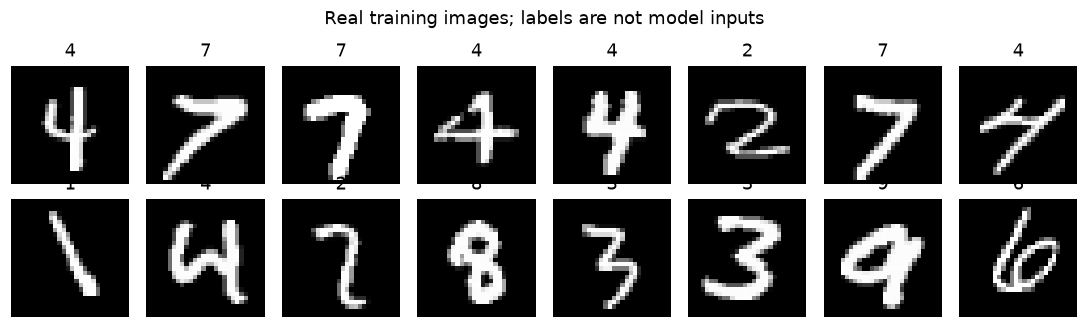

In [ ]:
train_set, val_set, manifest = prepare_mnist(ROOT / "data", seed=SEED)
assert set(train_set.indices).isdisjoint(val_set.indices)
print(
    {
        k: manifest[k]
        for k in [
            "train_count",
            "validation_count",
            "disk_bytes",
            "split_sha256",
            "official_test_used",
        ]
    }
)
print(
    [{k: r[k] for k in ["file", "bytes", "md5_verified", "sha256"]} for r in manifest["resources"]]
)
train_loader = DataLoader(
    train_set,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_set, 
    batch_size=64, 
    shuffle=False, 
    num_workers=0
)
images, labels = next(iter(train_loader))
assert images.shape == (64, 1, 28, 28) and images.min() >= -1 and images.max() <= 1

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, image, label in zip(axes.flat, images[:16], labels[:16]):
    ax.imshow((image[0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(int(label)))
    ax.axis("off")
fig.suptitle("Real training images; labels are not model inputs")
fig.tight_layout()
fig.savefig(OUT / "real_images.png")
plt.show()

#### **检查 1：真正看见 MNIST 数据从哪里来**

In [26]:
import inspect

print(inspect.getsource(prepare_mnist))
print(type(train_set))
print(type(train_set.dataset))
print(train_set[0][0].shape)
print(train_set[0][1])

def prepare_mnist(
    root: str | Path, *, train_size: int = 10000, validation_size: int = 1000, seed: int = 20261026
) -> tuple[Subset, Subset, dict]:
    root = Path(root)
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
    dataset = MNIST(root / "raw", train=True, transform=transform, download=True)
    if train_size <= 0 or validation_size <= 0 or train_size + validation_size > len(dataset):
        raise ValueError("MNIST 子集大小无效")
    order = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(seed)).tolist()
    train_ids, val_ids = order[:train_size], order[train_size : train_size + validation_size]
    payload = {"train": train_ids, "validation": val_ids}
    split_hash = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
    resources = []
    for filename, expected_md5 in dataset.resources:
        path = Path(dataset.raw_folder) / filename
        if not check_integrity(path, expected_m

#### **检查 2：真正看见 DataLoader 的输出**

In [29]:
batch = next(iter(train_loader))

print(type(batch))
print(len(batch))

images, labels = batch

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("前10个标签:", labels[:10])

<class 'list'>
2
Images: torch.Size([64, 1, 28, 28]) torch.float32
Labels: torch.Size([64]) torch.int64
前10个标签: tensor([6, 2, 4, 7, 2, 3, 6, 2, 6, 0])


#### **检查 3：真正看见生成循环的实现**

In [30]:
print(inspect.getsource(sample_ddpm))

@torch.no_grad()
def sample_ddpm(model, scheduler, initial_noise, *, seed=123, max_seconds=300, capture=None):
    if max_seconds <= 0:
        raise ValueError("采样时间上限必须为正")
    device = initial_noise.device
    generator = torch.Generator(device="cpu").manual_seed(seed)
    was_training = model.training
    model.eval()
    state = initial_noise.clone()
    snapshots = {"initial": state.cpu().clone()}
    capture = set(capture or [749, 499, 249, 99, 0])
    start = time.monotonic()
    completed_steps = 0
    for timestep in reversed(range(scheduler.num_steps)):
        if time.monotonic() - start >= max_seconds:
            break
        times = torch.full((len(state),), timestep, dtype=torch.long, device=device)
        prediction = model(state, times)
        noise = torch.randn(state.shape, generator=generator).to(device)
        state = scheduler.step(prediction, timestep, state, noise)
        if not torch.isfinite(state).all().item():
            raise FloatingPointError(f"采样在

### **2. 观察加噪，并区分边际视图与真实轨迹**

下图对同一真图在多个时间直接加噪，并固定同一份标准噪声，便于看信号如何减弱。它是多个边际分布的一种耦合可视化，不是每一步独立加噪的真实前向链。图题使用代码索引 k；数学时间为 k+1。

torch.Size([1, 1, 28, 28])


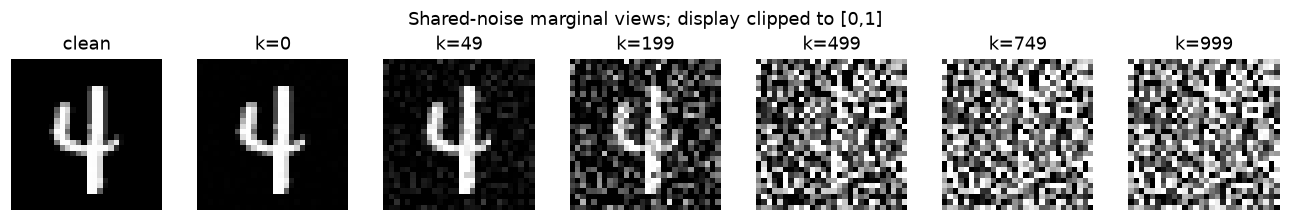

In [ ]:
selected = [0, 49, 199, 499, 749, 999]
base = images[:1]
print(base.shape)
noise = torch.randn(
    base.shape, 
    generator=torch.Generator().manual_seed(11)
)

fig, axes = plt.subplots(1, 7, figsize=(12, 2))

axes[0].imshow((base[0, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("clean")
axes[0].axis("off")
for ax, k in zip(axes[1:], selected):
    noised = reference_cpu.add_noise(base, noise, torch.tensor([k]))
    ax.imshow((noised[0, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k={k}")
    ax.axis("off")
    
fig.suptitle("Shared-noise marginal views; display clipped to [0,1]")
fig.tight_layout()
fig.savefig(OUT / "forward_noise.png")
plt.show()

### **3. U-Net 怎样把时间与图像结合起来**

U-Net 先降采样获得较大感受野，再上采样恢复空间分辨率；跳跃连接把高分辨率信息送到解码端。这里不用注意力、预训练权重或类别条件，保持第一周网络可理解。

| 位置 | 输出形状（base=32） | 作用 |
| --- | --- | --- |
| 输入 | `[B,1,28,28]` | 带噪图像 |
| enc1 | `[B,32,28,28]` | 局部特征，保留 skip1 |
| enc2 | `[B,64,14,14]` | 较大感受野，保留 skip2 |
| middle | `[B,128,7,7]` | 低分辨率特征 |
| dec2 | `[B,64,14,14]` | 上采样后拼接 skip2 |
| dec1 | `[B,32,28,28]` | 上采样后拼接 skip1 |
| 输出卷积 | `[B,1,28,28]` | 与噪声标签同形状 |

整数时间先经过不同频率的正弦、余弦编码，再通过 MLP 得到 128 维向量。每个 TimeBlock 将它投影到相应通道后广播相加，使相同图像在不同时间可以得到不同预测。GroupNorm 不依赖 batch 的统计均值，适合这里的小 batch。

完整工程源码位于 `src/minigen/models/tiny_unet.py`。下面显示关键前向代码，实例化并检查输出和时间条件梯度；它是可复用去噪网络，不包含隐藏的扩散采样公式。

In [12]:
import inspect

print(inspect.getsource(TinyUNet.forward))
network = TinyUNet(base=32)
output = network(images[:2], torch.tensor([0, 999]))
assert output.shape == images[:2].shape
output.square().mean().backward()
assert network.time_embedding.mlp[0].weight.grad.abs().sum() > 0
print(
    {
        "parameters": sum(p.numel() for p in network.parameters()),
        "output_shape": list(output.shape),
        "time_gradient_finite": bool(
            torch.isfinite(network.time_embedding.mlp[0].weight.grad).all()
        ),
    }
)

    def forward(
        self,
        image: Float[Tensor, "b 1 h w"],
        timesteps: Int[Tensor, "b"],
    ) -> Float[Tensor, "b 1 h w"]:
        time = self.time_embedding(timesteps)
        skip1 = self.enc1(image, time)
        skip2 = self.enc2(self.down1(skip1), time)
        hidden = self.middle(self.down2(skip2), time)

        hidden = F.interpolate(hidden, size=skip2.shape[-2:], mode="nearest")
        hidden = self.dec2(torch.cat([hidden, skip2], dim=1), time)

        hidden = F.interpolate(hidden, size=skip1.shape[-2:], mode="nearest")
        hidden = self.dec1(torch.cat([hidden, skip1], dim=1), time)
        return self.out(hidden)

{'parameters': 654785, 'output_shape': [2, 1, 28, 28], 'time_gradient_finite': True}


#### **实验 A：观察时间条件的 Shape**

In [13]:
network = TinyUNet(base=32)

time_steps = torch.tensor([0, 999])

print("Time steps:", time_steps.shape)

# 时间编码
time = network.time_embedding(time_steps)

print("Time embedding:", time.shape)

# 第一个 TimeBlock 的时间投影
time_bias = network.enc1.time(time)

print("Time projection:", time_bias.shape)

# 扩展为空间可广播的形状
time_bias = time_bias[:, :, None, None]

print("Broadcast shape:", time_bias.shape)

Time steps: torch.Size([2])
Time embedding: torch.Size([2, 128])
Time projection: torch.Size([2, 32])
Broadcast shape: torch.Size([2, 32, 1, 1])


#### **实验 B：理解时间如何影响输出**

In [14]:
network = TinyUNet(base=32)
network.eval()

image = torch.randn(1, 1, 28, 28)

with torch.no_grad():

    noise_early = network(
        image,
        torch.tensor([10])
    )

    noise_late = network(
        image,
        torch.tensor([900])
    )

difference = (noise_early - noise_late).abs().mean()

print("Difference:", difference.item())

Difference: 0.04764306917786598


## **八、本地拟合检查与随机噪声训练**

### **1. 预算、设备短跑与固定探针**

本轮训练、拟合和采样合计上限约 30 分钟，不含下载与环境准备；每次更新或采样步在结束后检查时间，所以一项操作可能略跨过截止点。先实际运行几步，确认该网络在选定设备上的前向与反向可用，再启动有时间上限的训练。

固定探针由干净图、时间和噪声三元组组成，使训练前后的损失可比。它只用于诊断，不参与按测试集调参。随机训练中每次重新抽噪声与时间；固定小批次实验则故意固定所有输入，检查优化链是否能拟合一个明确映射，两者证明的能力不同。

In [16]:
import time
experiment_started = time.monotonic()       # monotonic() 单调时钟；deadline 用于记录训练时间、控制时间预算
experiment_deadline = experiment_started + 1800
seed_all(SEED)

warm_model = TinyUNet(base=32).to(DEVICE)
warm_scheduler = TeachingDDPMScheduler().to(DEVICE)
warm_x = images[:4].to(DEVICE)
warm_start = time.monotonic()
for _ in range(3):
    t = torch.randint(1000, (len(warm_x),), device=DEVICE)
    eps = torch.randn_like(warm_x)
    warm_model.zero_grad(set_to_none=True)
    warm_loss = warm_scheduler.loss(
        warm_model(
            warm_scheduler.add_noise(
                warm_x, eps, t), 
            t
        ), 
        eps
    )
    warm_loss.backward()
assert torch.isfinite(warm_loss)
print(
    {
        "warmup_steps": 3,
        "device": DEVICE,
        "seconds": time.monotonic() - warm_start,
        "loss": warm_loss.item(),
    }
)
del warm_model, warm_scheduler

{'warmup_steps': 3, 'device': 'mps', 'seconds': 0.6459888329263777, 'loss': 1.1534830331802368}


### **2. 固定 16 张图与固定监督目标的拟合检查**

固定数据、时间和噪声，训练 100 步，上限 3 分钟。观察同一探针的前后损失、梯度和曲线。即使它明显下降，也只说明网络能拟合这个监督映射，不证明从纯噪声生成的质量，更不代表验证泛化。

step=50 loss=0.07591 elapsed=2.5s
step=100 loss=0.01059 elapsed=4.9s
{'final_step': 100, 'stop_reason': 'max_steps', 'elapsed_seconds': 5.0601758329430595, 'initial_probe_loss': 1.0771076679229736, 'final_probe_loss': 0.009980934672057629}


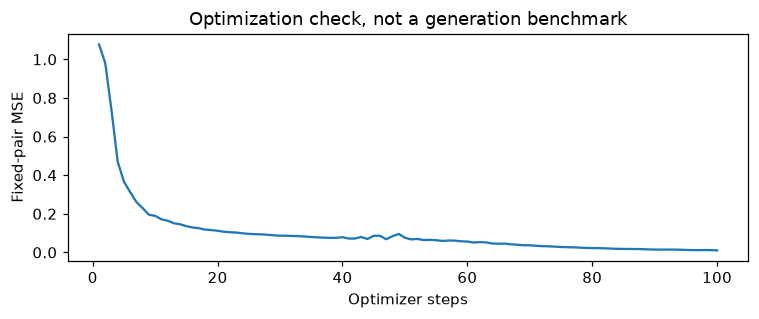

In [18]:
seed_all(SEED)
g = torch.Generator().manual_seed(21)

fixed_x = images[:16].clone()
fixed_eps = torch.randn(fixed_x.shape, generator=g)
fixed_t = torch.full((16,), 250, dtype=torch.long)
fixed_probe = (fixed_x, fixed_eps, fixed_t)

# Initialization
overfit_model = TinyUNet(base=32)
overfit_cfg = TrainConfig(
    run_dir=str(OUT / "fixed_pair"),
    max_steps=100,
    max_seconds=180,        # max_steps 和 max_seconds 是两个停止条件；通常哪个先达到，就按照哪个条件停止
    checkpoint_every=50,
    learning_rate=1e-3,
    device=DEVICE,
    seed=SEED,
    scheduler_source="notebook_reference",
)

# Training
overfit_result = train_denoiser(
    overfit_model,
    TeachingDDPMScheduler(),
    [(fixed_x,)],
    overfit_cfg,
    probe=fixed_probe,
    fixed_batch=fixed_probe,
)

print(
    {
        k: overfit_result[k]
        for k in [
            "final_step",
            "stop_reason",
            "elapsed_seconds",
            "initial_probe_loss",
            "final_probe_loss",
        ]
    }
)

# Displaying Curves
assert overfit_result["final_step"] > 0
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(
    [r["step"] for r in overfit_result["metrics"]], [r["loss"] for r in overfit_result["metrics"]]
)
ax.set(
    xlabel="Optimizer steps",
    ylabel="Fixed-pair MSE",
    title="Optimization check, not a generation benchmark",
)
fig.tight_layout()
fig.savefig(OUT / "fixed_pair_loss.png")
plt.show()

In [19]:
initial = overfit_result["initial_probe_loss"]
final = overfit_result["final_probe_loss"]

print("初始损失:", initial)
print("最终损失:", final)
print("损失比例:", final / initial)

初始损失: 1.0771076679229736
最终损失: 0.009980934672057629
损失比例: 0.009266422447167452


In [20]:
model = overfit_model.to(DEVICE)
model.eval()

scheduler = TeachingDDPMScheduler().to(DEVICE)

x0 = fixed_x.to(DEVICE)
t = fixed_t.to(DEVICE)

new_eps = torch.randn_like(x0)

with torch.no_grad():
    new_xt = scheduler.add_noise(x0, new_eps, t)
    new_pred = model(new_xt, t)

    new_loss = scheduler.loss(new_pred, new_eps)

print("新的随机噪声 Loss:", new_loss.item())

新的随机噪声 Loss: 0.0843837782740593


### **3. 随机时间与噪声的 MNIST 短训练**

这次重新初始化网络，不沿用固定小批次拟合权重。每次取真实图、抽噪声和时间，构造输入，预测噪声，平均 MSE，反向传播，裁剪梯度，更新 AdamW，再更新 EMA。EMA 是训练权重的指数滑动平均，本实验衰减为 0.99，采样使用其权重；它不等于额外训练一个网络。

最多 1000 次优化器更新，或 15 分钟训练时间，先达到者停止。batch 64；学习率 0.0002；无梯度累积；float32。10000 张图像的数据子集不等于 10000 次更新。重复经历同一数据并不能证明泛化，需要观察独立验证探针和最终样本。

Checkpoint 保存模型、优化器、EMA、步数、配置与随机状态。当前只验证基本恢复，不承诺带 shuffle 的 DataLoader 在 epoch 中途恢复相同后续样本顺序。

step=100 loss=0.07383 elapsed=13.5s
step=200 loss=0.07197 elapsed=25.8s
step=300 loss=0.04609 elapsed=39.3s
step=400 loss=0.05710 elapsed=54.2s
step=500 loss=0.04483 elapsed=67.0s
step=600 loss=0.02766 elapsed=80.0s
step=700 loss=0.02856 elapsed=94.7s
step=800 loss=0.04198 elapsed=110.2s
step=900 loss=0.04208 elapsed=123.8s
step=1000 loss=0.02803 elapsed=137.2s
{'final_step': 1000, 'stop_reason': 'max_steps', 'elapsed_seconds': 137.50362520792987, 'initial_probe_loss': 1.0817253589630127, 'final_probe_loss': 0.032044146209955215, 'ema_probe_loss': 0.03137407451868057, 'resume_limitation': 'No shuffled-loader mid-epoch order restoration'}


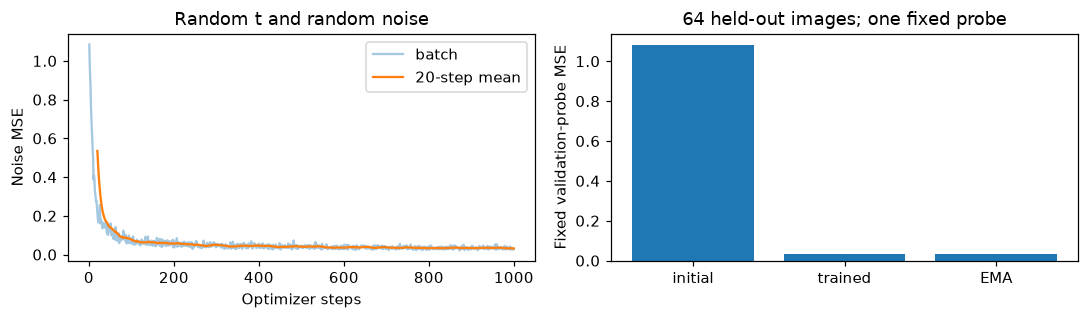

In [ ]:
val_images, _ = next(iter(val_loader))
g = torch.Generator().manual_seed(31)
val_probe = (
    val_images,
    torch.randn(val_images.shape, generator=g),
    torch.randint(1000, (len(val_images),), generator=g),
)
seed_all(SEED)

model = TinyUNet(base=32)
training_seconds = min(900, max(1, experiment_deadline - time.monotonic() - 300))
train_cfg = TrainConfig(
    run_dir=str(OUT / "mnist_short"),
    max_steps=1000,
    max_seconds=training_seconds,
    checkpoint_every=100,
    device=DEVICE,
    seed=SEED,
    scheduler_source="notebook_reference",
)
training_result = train_denoiser(
    model, TeachingDDPMScheduler(), train_loader, train_cfg, probe=val_probe
)
print(
    {
        k: training_result[k]
        for k in [
            "final_step",
            "stop_reason",
            "elapsed_seconds",
            "initial_probe_loss",
            "final_probe_loss",
            "ema_probe_loss",
            "resume_limitation",
        ]
    }
)
rows = training_result["metrics"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
losses = np.array([r["loss"] for r in rows])
steps = np.array([r["step"] for r in rows])
axes[0].plot(steps, losses, alpha=0.4, label="batch")
if len(losses) >= 20:
    axes[0].plot(
        steps[19:], np.convolve(losses, np.ones(20) / 20, mode="valid"), label="20-step mean"
    )
axes[0].set(xlabel="Optimizer steps", ylabel="Noise MSE", title="Random t and random noise")
axes[0].legend()
axes[1].bar(
    ["initial", "trained", "EMA"],
    [
        training_result["initial_probe_loss"],
        training_result["final_probe_loss"],
        training_result["ema_probe_loss"],
    ],
)
axes[1].set(ylabel="Fixed validation-probe MSE", title="64 held-out images; one fixed probe")
fig.tight_layout()
fig.savefig(OUT / "training_loss.png")
plt.show()

## **九、完整反向采样、恢复检查与结果判断**

### **1. 固定噪声，完整走过反向链**

从全新标准高斯噪声开始，用训练所得 EMA 预测噪声；从代码索引 999 到 0 每一级都执行。本实验没有 CFG，没有跳步，也没有用 DDIM 代替 DDPM。每步更新可理解为“估计干净图 → 计算后验均值 → 除最后一步外加入后验标准差乘新噪声”。

初始噪声和采样随机种子固定，便于之后比较权重。中间状态保留作轨迹可视化；只有全部 1000 步完成才标记 completed。如果触及时间上限，输出只能叫未完成轨迹，不能当作最终生成样本。下面重新加载 EMA 权重，避免只凭训练对象还在内存中宣称可加载。

{'completed': True, 'completed_steps': 1000, 'elapsed_seconds': 8.325083666015416, 'seed': 42, 'model_calls': 1000}


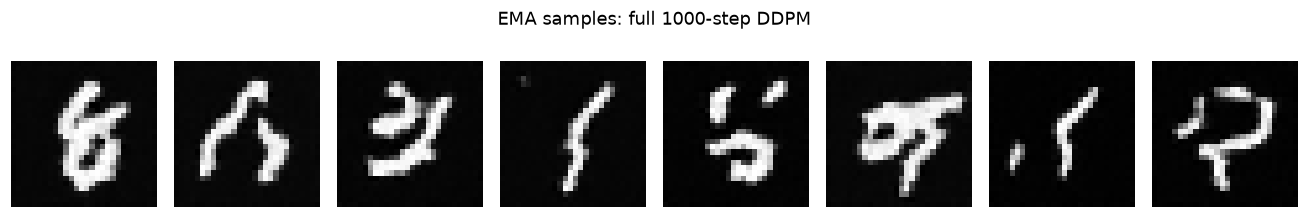

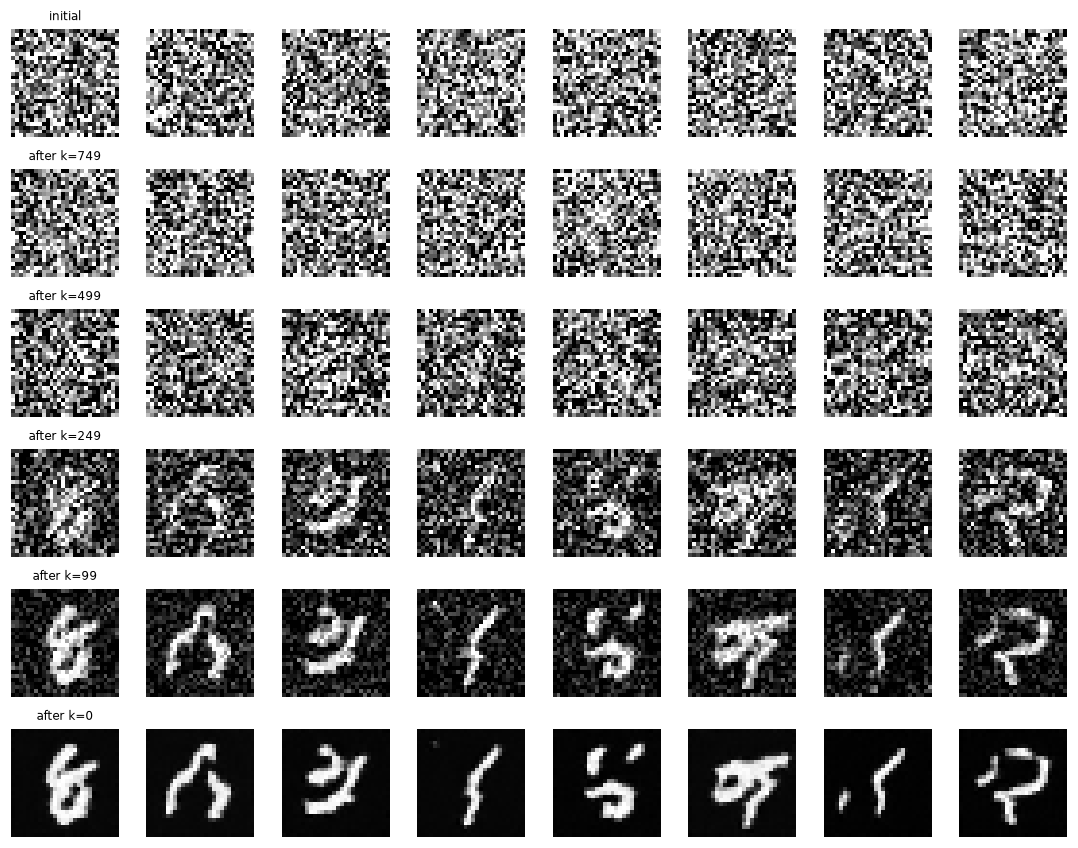

In [ ]:
checkpoint = torch.load(training_result["checkpoint"], map_location="cpu", weights_only=True)
sampling_model = TinyUNet(base=32).to(DEVICE)
sampling_model.load_state_dict(checkpoint["ema"])

initial_noise = torch.randn(
    (8, 1, 28, 28), 
    generator=torch.Generator().manual_seed(41)
).to(DEVICE)
sampling_result = sample_ddpm(
    sampling_model,
    TeachingDDPMScheduler(clip_denoised=True).to(DEVICE),
    initial_noise,
    seed=42,
    max_seconds=min(300, max(0.1, experiment_deadline - time.monotonic())),
)
print(
    {
        k: sampling_result[k]
        for k in ["completed", "completed_steps", "elapsed_seconds", "seed", "model_calls"]
    }
)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image in zip(axes, sampling_result["images"]):
    ax.imshow((image[0].clamp(-1, 1) + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(
    "EMA samples: full 1000-step DDPM"
    if sampling_result["completed"]
    else "INCOMPLETE trajectory; not final samples"
)
fig.tight_layout()
fig.savefig(OUT / "generated_samples.png")
plt.show()
states = sampling_result["snapshots"]
fig, axes = plt.subplots(len(states), 8, figsize=(10, 1.3 * len(states)), squeeze=False)
for row, (name, batch) in enumerate(states.items()):
    for col, (ax, image) in enumerate(zip(axes[row], batch)):
        ax.imshow((image[0].clamp(-1, 1) + 1) / 2, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if col == 0:
            ax.set_title("initial" if name == "initial" else f"after k={name}", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "reverse_trajectory.png")
plt.show()

### **2. 如何理解这些训练结果，而不过度解释**

读结果时分四层：

1. 数学和优化链路是否正确：独立后验对照、梯度与固定输入拟合有没有通过？
2. 独立验证探针是否改善：这里只是 64 张验证图和固定噪声时间，不能代替完整统计评测。
3. 从新噪声采样是否出现数字结构：检查完整固定批次，不只挑最好一张。
4. 能否证明覆盖所有类别、避免记忆和稳定泛化：本轮的短训练与 8 张样本不足以证明这些结论，不报告 FID 或性能提升百分比。

常见失败包括笔画断裂、多个数字黏连、局部灰块或很少变化。它们可能与训练量、网络容量、噪声目标、采样日程或数据处理有关。先核对独立数学检查和归一化，再比较验证损失与样本；不能看到灰块就直接归因于“模型太小”。下面保存真实数值与完整样本，具体视觉观察在阶段报告中记录。

**本次保存的执行结果**（重跑后以新的代码输出为准）：固定 16 图监督的 MSE 从约 1.0771 降到 0.00998；随机训练完成 1000 步，64 图固定验证探针从约 1.0817 降到 0.03204，EMA 为约 0.03137。完整采样 1000 步得到 8 张图。

观察全批次：已出现竖直、弯曲和闭合笔画，有几张较像数字；同时存在笔画黏连、变形、零散亮点和语义不清。没有逐张真值，不能从“看起来像某个数字”计算分类准确率；8 张也不足以证明类别覆盖、无记忆或稳定性。CPU 固定单批次的 6 步连续/3+3 步恢复对照在参数与 EMA 上逐位相同，但未验证随机 DataLoader 的中途顺序恢复。

| 字段 | 保存什么 | 意义 |
|---|---|---|
| `scheduler_source` | `"notebook_reference"` | 使用的 Scheduler 来源 |
| `src_core_implemented` | `False` | 标记个人核心实现是否完成 |
| `seed` | `SEED` | 实验随机种子 |
| `device` | `DEVICE` | CPU、MPS 或 CUDA |
| `torch_version` | PyTorch 版本 | 记录运行环境 |
| `data` | 数据量、划分哈希等 | 记录使用了哪些数据 |
| `data_resources` | MNIST 数据文件信息 | 数据来源和校验信息 |
| `math_checks` | 数学检查结果 | 记录之前的公式检查 |
| `oracle_max_error` | 数值对照最大误差 | 检查实现与参考结果的差异 |
| `fixed_pair` | 固定过拟合结果 | 检查训练链路是否正常 |
| `training` | 正式训练结果 | 保存训练步数和验证损失 |
| `sampling` | 反向生成结果 | 记录采样是否完成 |
| `config` | 训练配置 | 保存超参数 |
| `limitations` | 实验局限 | 避免过度解释结果 |

In [33]:
summary = {
    "scheduler_source": "notebook_reference",
    "src_core_implemented": False,
    "seed": SEED,
    "device": DEVICE,
    "torch_version": str(torch.__version__),
    "data": {
        k: manifest[k]
        for k in [
            "train_count",
            "validation_count",
            "disk_bytes",
            "split_sha256",
            "official_test_used",
        ]
    },
    "data_resources": manifest["resources"],
    "math_checks": math_checks,
    "oracle_max_error": error,
    "fixed_pair": {
        k: overfit_result[k]
        for k in [
            "final_step",
            "stop_reason",
            "elapsed_seconds",
            "initial_probe_loss",
            "final_probe_loss",
        ]
    },
    "training": {
        k: training_result[k]
        for k in [
            "final_step",
            "stop_reason",
            "elapsed_seconds",
            "initial_probe_loss",
            "final_probe_loss",
            "ema_probe_loss",
        ]
    },
    "sampling": {
        k: sampling_result[k]
        for k in ["completed", "completed_steps", "elapsed_seconds", "seed", "model_calls"]
    },
    "config": training_result["config"],
    "experiment_elapsed_seconds": time.monotonic() - experiment_started,
    "limitations": [
        "8 samples only",
        "64-image fixed validation probe",
        "single training seed",
        "no shuffled-loader mid-epoch replay",
        "not a paper reproduction",
    ],
}
(OUT / "notebook_results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "scheduler_source": "notebook_reference",
  "src_core_implemented": false,
  "seed": 20261026,
  "device": "mps",
  "torch_version": "2.14.1",
  "data": {
    "train_count": 10000,
    "validation_count": 1000,
    "disk_bytes": 66544770,
    "split_sha256": "caae80b4d0f9cc96b9761366f6d22d0597677efdd880dd86d6837ec3312fbde9",
    "official_test_used": false
  },
  "data_resources": [
    {
      "file": "raw/MNIST/raw/train-images-idx3-ubyte.gz",
      "bytes": 9912422,
      "expected_md5": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
      "md5_verified": true,
      "sha256": "440fcabf73cc546fa21475e81ea370265605f56be210a4024d2ca8f203523609"
    },
    {
      "file": "raw/MNIST/raw/train-labels-idx1-ubyte.gz",
      "bytes": 28881,
      "expected_md5": "d53e105ee54ea40749a09fcbcd1e9432",
      "md5_verified": true,
      "sha256": "3552534a0a558bbed6aed32b30c495cca23d567ec52cac8be1a0730e8010255c"
    },
    {
      "file": "raw/MNIST/raw/t10k-images-idx3-ubyte.gz",
      "bytes": 164887

### **3. CPU 小案例的保存与恢复对照**

用同一份教学 Scheduler 和一个只有 1×1 卷积的最小噪声预测器，比较连续 6 步与 3 步保存后再恢复到第 6 步。使用固定单批次、CPU、相同初始权重，检查模型与 EMA 逐位相同。该实验检查保存、优化器、随机状态和更新衔接，不是 MNIST 生成实验，也不证明随机 DataLoader 的中途顺序恢复。

In [24]:
class MinimalDenoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 1, 1)

    def forward(self, image, times):
        return self.conv(image)


seed_all(51)
start_model = MinimalDenoiser()
mini_loader = [(torch.zeros(2, 1, 4, 4),)]
full_model = copy.deepcopy(start_model)
full_result = train_denoiser(
    full_model,
    TeachingDDPMScheduler(num_steps=20),
    mini_loader,
    TrainConfig(str(OUT / "resume_full"), max_steps=6, max_seconds=30, checkpoint_every=6),
)
partial_result = train_denoiser(
    copy.deepcopy(start_model),
    TeachingDDPMScheduler(num_steps=20),
    mini_loader,
    TrainConfig(str(OUT / "resume_partial"), max_steps=3, max_seconds=30, checkpoint_every=3),
)
resumed_model = MinimalDenoiser()
resumed_result = train_denoiser(
    resumed_model,
    TeachingDDPMScheduler(num_steps=20),
    mini_loader,
    TrainConfig(str(OUT / "resume_restarted"), max_steps=6, max_seconds=30, checkpoint_every=6),
    resume_path=partial_result["checkpoint"],
)
for a, b in zip(full_model.parameters(), resumed_model.parameters()):
    torch.testing.assert_close(a, b, rtol=0, atol=0)
full_saved = torch.load(full_result["checkpoint"], weights_only=True, map_location="cpu")
resumed_saved = torch.load(resumed_result["checkpoint"], weights_only=True, map_location="cpu")
for key in full_saved["ema"]:
    torch.testing.assert_close(full_saved["ema"][key], resumed_saved["ema"][key], rtol=0, atol=0)
summary["cpu_fixed_loader_resume_exact"] = True
summary["experiment_elapsed_seconds"] = time.monotonic() - experiment_started
(OUT / "notebook_results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
print({"cpu_resume_exact": True, "ema_exact": True, "shuffled_loader_replay_verified": False})

step=6 loss=1.32615 elapsed=0.0s
step=3 loss=1.31763 elapsed=0.0s
step=6 loss=1.32615 elapsed=0.0s
{'cpu_resume_exact': True, 'ema_exact': True, 'shuffled_loader_replay_verified': False}


## **十、把参考知识转化为自己的核心实现**

### **1. 下一份动手任务：S1-03 / L01**

不要把整段参考类复制进 `src` 后直接勾选完成。先合上参考代码，用自己的符号画出训练与采样流程，再完成项目 `DDPMScheduler`：

- 初始化 beta、alpha、累计 alpha 及前一累计系数，解释首项为什么是 1。
- 实现 `add_noise`，支持每个 batch 样本不同时间，并检查广播。
- 实现 `loss`，说明平均了哪些维度，验证一个手算梯度。
- 实现 `step`，明确方差选择、是否裁剪估计干净图和最后一步行为。
- 让 Agent 准备独立的标量、统计、边界和梯度测试；通过后再把自己的 Scheduler 显式接入同一训练工程。

如果沿用当前非 nn.Module 接口，需要自己处理系数的设备移动；如果改为 nn.Module，说明 buffer 为什么不需要梯度。参考实现仅供学习，项目当前核心仍是未实现状态。

### **2. 自测题与参考解答**

**问题 1：为什么训练一次更新不用执行前向 1000 步？**

因为已经推导了任意时间的边际分布，可以直接用干净图和一份标准噪声抽取 $x_t$。这不意味着采样时可以任意跳过反向步骤。

**问题 2：如果网络知道真实噪声，就能恢复 $x_0$，为什么还要训练？**

真实噪声只在我们构造训练输入时已知。生成时只有新的带噪状态，网络必须从数据中学习条件统计信息。Oracle 恢复是公式验算，不是生成能力。

**问题 3：前向方差、累计噪声方差、反向后验方差分别是什么？**

分别是 $\beta_t$、$1-\bar\alpha_t$、$\widetilde\beta_t$；采样乘的是对应标准差。不能因为三者都叫噪声就混用。

**问题 4：代码时间索引 0 是干净图吗？**

不是，它对应数学时间 1，已经加噪一次。反向索引 0 才是返回最后估计干净图的更新，不再加入额外噪声。

**问题 5：简单噪声 MSE 等于完整变分界吗？**

不完全等于。它去掉时间权重，并用统一噪声回归处理所有时间；完整变分界还有终点和重建项。当前代码没有实现精确似然评测。

**问题 6：固定小批次 loss 降低，能说明样本质量好吗？**

不能。它只验证优化链能拟合指定监督映射；还需查看独立验证、从新噪声完整生成和更充分评测。

**问题 7：EMA 为什么可能与当前模型不同？**

EMA 平滑历史参数，可能降低训练波动，但存在滞后；不能假定任何训练长度下它都更好。本笔记分别记录两者的固定验证探针损失。

**问题 8：CPU 恢复对照通过后，能否声称任意训练都完全恢复？**

不能。这里没有实现随机 DataLoader 的 epoch 中途样本顺序恢复，跨设备也不能承诺逐位相同。恢复结论只适用于已经验证的条件。

### **3. 来源、局限与下一周**

主要来源：[DDPM](https://arxiv.org/abs/2006.11239)、[作者代码](https://github.com/hojonathanho/diffusion)、[Torchvision MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)。后验公式、噪声参数化与简化目标以原论文为依据；当前小型网络、子集、训练量和工程工具是本项目的教学选择，未使用作者模型权重。

本轮只训练一个种子、有限子集和短步数，展示 8 张固定样本与一份固定验证探针。它提供数学、工程和初步生成证据，不承担完整质量 Benchmark、全部类别覆盖或开放域能力结论。

下一周进入 VAE：先解释为什么要压缩图像、编码器为何输出分布、重参数化与 KL 约束如何工作，再研究潜空间生成。DDPM 的噪声过程与 VAE 的潜变量分布不是同一个概念。